
ALL-STATION FREQUENCY STABILITY — DEPTH
NPY root: /media/alan/JARVIS/TRANSCORBE/ACF_CCF_12_HHZ_new_2
Detected station directories: 41
Usable frequency bands: 8
Stack method: linear
Phase shift: phase-shifted (90 deg) then stacked
Sampling interval: 0.2 s
Nyquist frequency: 2.5 Hz
Depth range: (0.0, 75.0) km

Station-specific reference depths
station |    dist |     UC ref |     LC ref |    Ib Moho
TR43    |   17.11 |        n/a |        n/a |   38.40 km
TR42    |   19.55 |        n/a |        n/a |   38.80 km
TR40    |   22.27 |        n/a |   15.42 km |   39.15 km
TR41    |   22.59 |        n/a |   15.44 km |   39.19 km
TR38    |   31.20 |        n/a |   14.40 km |   39.96 km
TR37    |   35.30 |        n/a |   14.09 km |   40.63 km
TR36    |   39.83 |        n/a |   13.73 km |   41.00 km
TR35    |   45.08 |        n/a |   13.65 km |   40.59 km
TR34    |   48.14 |        n/a |   13.89 km |   40.19 km
TR32N   |   55.15 |   12.03 km |   22.25 km |   39.62 km
TR32    |   55.20 |   12.04 

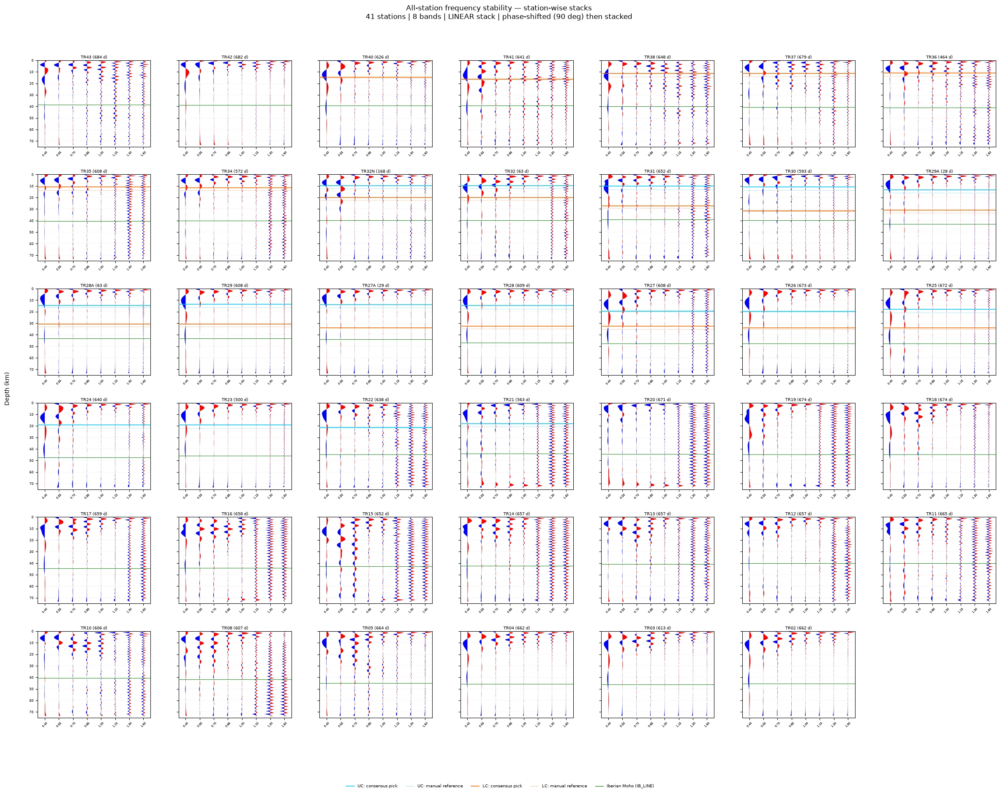

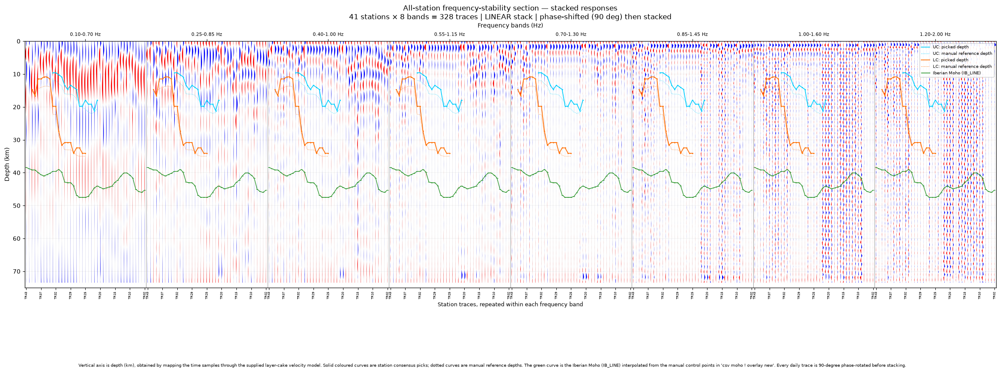

In [ ]:
# ALL-STATION ACF-CCF FREQUENCY STABILITY — DEPTH SECTIONS


import re
import math
import calendar
import warnings
from pathlib import Path
from datetime import datetime, timedelta
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt, hilbert
from scipy.ndimage import gaussian_filter1d
from scipy.interpolate import PchipInterpolator
from matplotlib.lines import Line2D
from obspy import read_inventory
from obspy.geodetics import gps2dist_azimuth


NPY_ROOT = Path(
    r"/media/alan/JARVIS/TRANSCORBE/ACF_CCF_12_HHZ_new_2"
)

STATIONXML = Path(
    r"/media/alan/JARVIS/TRANSCORBE/TRANSCORBE.xml"
)

# None / None = all available daily files per station.
START_DATE = None
N_DAYS = None

# Optional:
# START_DATE = "2013-07-01"
# N_DAYS = 30

DT = 0.2
MAXLAG_SEC = 20.0

# Original waveform passband used to create the NPY files.
SOURCE_BAND = (0.1, 2.0)

# Overlapping frequency bands in Hz.
FREQUENCY_BANDS = [
    (0.10, 0.70),
    (0.25, 0.85),
    (0.40, 1.00),
    (0.55, 1.15),
    (0.70, 1.30),
    (0.85, 1.45),
    (1.00, 1.60),
    (1.20, 2.00),
]

FILTER_ORDER = 3
MIN_EFFECTIVE_BANDWIDTH_HZ = 0.20

FILTER_FS = 1.0 / DT
NYQUIST = FILTER_FS / 2.0


# ============================================================
# 3. STACK SETTINGS
# ============================================================

STACK_METHOD = "linear"       # "linear" or "pws"
PWS_POWER = 2

# Hilbert-style 90 degree phase rotation applied to every
# daily trace BEFORE the stack is formed.
#
# This matches the phase_shift() applied in
# "csv moho ! overlay new":
#   section_linear = [phase_shift(tr) for tr in section_linear]
#   section_pws    = [pws([phase_shift(tr) for tr in traces]) ...]
#
#   True  -> rotate each daily trace, then stack.
#   False -> stack the raw bandpassed ACFs (unrotated).
APPLY_PHASE_SHIFT = True


# ============================================================
# 4. PROFILE GEOMETRY
# ============================================================

PROFILE_START = (38.33, -3.08)
PROFILE_END = (37.43, -1.08)


# ============================================================
# 5. DISPLAY SETTINGS — ALL DEPTH BASED
# ============================================================

GRID_FIGSIZE = (24, 19)
SECTION_FIGSIZE = (24, 9)

GRID_NCOLS = 7

# Amplitude gain is a display parameter.
PANEL_AMP_GAIN = 1.0
SECTION_AMP_GAIN = 1.0

PANEL_TRACE_WIDTH = 0.32
SECTION_TRACE_WIDTH = 0.38

NORMALIZE_STACKS = True

# Vertical axis in km. The 20 s TWT window corresponds to
# approximately 73.46 km under the velocity model below.
PLOT_DEPTH_RANGE = (0.0, 75.0)

# Search around each station's model-derived LC/UC reference.
# This is a half-width in DEPTH, not seconds.
PICK_HALF_WINDOW_KM = 3.0

PICK_SMOOTH_SIGMA = 0.7

UC_COLOR = "#00cfff"
LC_COLOR = "#ff6d00"
IB_COLOR = "green"


# ============================================================
# 6. MANUAL IBERIAN MOHO FROM "csv moho ! overlay new"
# ============================================================
#
# Copied verbatim from the overlay script (IB_LINE).
# X = profile distance (km)
# Y = depth (km)
#
# This is the ONLY source of the station Moho depth plotted
# in the two figures. No hard-coded TWT table is used.
#
# Same (x, y, linestyle) tuple shape as LC_SEGMENTS / UC_SEGMENTS,
# so the existing `interpolate_segmented_horizon` helper works
# unchanged on this list.
# ============================================================

IB_LINE = [
    (
        np.array([15, 21, 32], dtype=float),
        np.array([38, 39, 40], dtype=float),
        "-",
    ),
    (
        np.array([32, 40, 50, 57], dtype=float),
        np.array([40, 41, 40, 39.5], dtype=float),
        "-",
    ),
    (
        np.array([57, 60, 65, 70, 80, 90, 98], dtype=float),
        np.array([39.5, 39, 42, 47.5, 47.5, 44, 45], dtype=float),
        "-",
    ),
    (
        np.array([98, 122, 130, 140, 160, 168], dtype=float),
        np.array([45, 42, 40, 41.5, 46, 44.5], dtype=float),
        "--",
    ),
]


# ============================================================
# 7. LC/UC MANUAL PROFILE SEGMENTS FROM YOUR LATEST CODE
# ============================================================
#
# X = profile distance (km)
# Y = depth (km)
#
# Preserve the segments and gaps in the source definition.
# Do not extrapolate beyond each defined segment.
# ============================================================

LC_SEGMENTS = [
    (
        np.array([20, 25, 27], dtype=float),
        np.array([15, 15.5, 14.65], dtype=float),
        "-",
    ),
    (
        np.array([27, 32, 38], dtype=float),
        np.array([14.65, 14.35, 13.85], dtype=float),
        "-",
    ),
    (
        np.array([38, 45, 47.5, 50], dtype=float),
        np.array([13.85, 13.65, 13.85, 14.0], dtype=float),
        "-",
    ),
    (
        np.array([50, 60], dtype=float),
        np.array([14.0, 30.0], dtype=float),
        "--",
    ),
    (
        np.array([60, 65, 70, 80], dtype=float),
        np.array([30.0, 32.5, 35.0, 35.0], dtype=float),
        "-",
    ),
]

UC_SEGMENTS = [
    (
        np.array([55, 62], dtype=float),
        np.array([12.0, 13.5], dtype=float),
        "-",
    ),
    (
        np.array([62, 75, 80], dtype=float),
        np.array([13.5, 20.0, 21.0], dtype=float),
        "-",
    ),
    (
        np.array([80, 85, 90, 95], dtype=float),
        np.array([21.0, 22.0, 21.0, 20.0], dtype=float),
        "-",
    ),
]


# ============================================================
# 8. DEPTH-TWT CONVERSION
# ============================================================

CRUST_LAYERS = [
    (10.0, 6.0),
    (10.0, 6.4),
    (10.0, 6.8),
]

V_MANTLE = 8.2


def twt_to_depth(twt_s):
    """
    Convert TWT in seconds to depth in km using the existing
    layer-cake P-wave velocity model.
    """

    if not np.isfinite(twt_s) or twt_s < 0:
        return np.nan

    remaining_time = float(twt_s) / 2.0
    depth = 0.0

    for thickness, velocity in CRUST_LAYERS:

        layer_time = thickness / velocity

        if remaining_time <= layer_time:
            depth += remaining_time * velocity
            remaining_time = 0.0
            break

        depth += thickness
        remaining_time -= layer_time

    if remaining_time > 0:
        depth += remaining_time * V_MANTLE

    return float(depth)


def depth_to_twt(depth_km):
    """Convert depth in km to TWT in seconds."""

    if not np.isfinite(depth_km) or depth_km < 0:
        return np.nan

    remaining_depth = float(depth_km)
    one_way_time = 0.0

    for thickness, velocity in CRUST_LAYERS:

        if remaining_depth <= thickness:
            one_way_time += remaining_depth / velocity
            remaining_depth = 0.0
            break

        one_way_time += thickness / velocity
        remaining_depth -= thickness

    if remaining_depth > 0:
        one_way_time += remaining_depth / V_MANTLE

    return float(2.0 * one_way_time)


def build_depth_axis(lag_s):
    """
    Map every time-domain sample to depth.
    Filtering and stacking remain in the original time-sampled domain.
    """

    return np.array(
        [twt_to_depth(t) for t in lag_s],
        dtype=float,
    )


# ============================================================
# 9. PHASE SHIFT (HILBERT-STYLE 90 DEG ROTATION)
# ============================================================

def phase_shift(trace, dt=DT):
    """
    Hilbert-style 90 degree phase rotation.

    Multiplies positive frequencies by exp(-i*pi/2),
    negative frequencies by exp(+i*pi/2), and leaves DC
    untouched. Identical formula to the phase_shift()
    function used in "csv moho ! overlay new".
    """
    x = np.asarray(trace, dtype=float)
    n = x.size
    freqs = np.fft.fftfreq(n, d=dt)
    F = np.fft.fft(x)
    ps = np.where(
        freqs > 0, np.exp(-1j * np.pi / 2.0),
        np.where(
            freqs < 0,
            np.exp( 1j * np.pi / 2.0),
            1.0,
        ),
    )
    return np.real(np.fft.ifft(F * ps))


# ============================================================
# 10. PROJECT STATIONS ONTO THE PROFILE
# ============================================================

def get_station_profile_distances(stations):

    if not STATIONXML.is_file():
        raise FileNotFoundError(
            f"StationXML not found: {STATIONXML}"
        )

    inventory = read_inventory(str(STATIONXML))

    station_coords = {}

    for network in inventory:
        for station in network:
            station_coords[station.code] = (
                station.latitude,
                station.longitude,
            )

    _, profile_azimuth, _ = gps2dist_azimuth(
        PROFILE_START[0],
        PROFILE_START[1],
        PROFILE_END[0],
        PROFILE_END[1],
    )

    distances = {}

    for station in stations:

        if station not in station_coords:
            warnings.warn(
                f"{station} not found in StationXML; "
                "profile distance is unavailable."
            )
            distances[station] = np.nan
            continue

        lat, lon = station_coords[station]

        distance_m, station_azimuth, _ = gps2dist_azimuth(
            PROFILE_START[0],
            PROFILE_START[1],
            lat,
            lon,
        )

        projected_km = (
            distance_m
            * np.cos(
                np.deg2rad(
                    station_azimuth - profile_azimuth
                )
            )
            / 1000.0
        )

        distances[station] = float(projected_km)

    return distances


# ============================================================
# 11. INTERPOLATE SEGMENTED HORIZONS AT EACH STATION
# ============================================================

def interpolate_segmented_horizon(distance_km, segments):
    """
    Interpolate a manual segmented horizon within its defined
    segments. Returns NaN outside the segments; no extrapolation.

    Used for LC_SEGMENTS, UC_SEGMENTS, and IB_LINE — all share
    the same (x, y, linestyle) tuple layout.
    """

    if not np.isfinite(distance_km):
        return np.nan

    for x, y, linestyle in segments:

        if x.min() <= distance_km <= x.max():

            interp = PchipInterpolator(
                x,
                y,
                extrapolate=False,
            )

            return float(interp(distance_km))

    return np.nan


def build_station_horizon_references(
    station_order,
    profile_distances,
):
    """
    Each station receives:
      - one LC reference depth  (from LC_SEGMENTS)
      - one UC reference depth  (from UC_SEGMENTS)
      - one Iberian Moho depth  (from IB_LINE)

    All three are interpolated at the station's projected
    profile distance. No global straight-line horizon is used.
    """

    references = {}

    print("\nStation-specific reference depths")
    print(
        f"{'station':7s} | {'dist':>7s} | "
        f"{'UC ref':>10s} | {'LC ref':>10s} | {'Ib Moho':>10s}"
    )

    for station in station_order:

        distance = profile_distances.get(
            station,
            np.nan,
        )

        lc_depth = interpolate_segmented_horizon(
            distance,
            LC_SEGMENTS,
        )

        uc_depth = interpolate_segmented_horizon(
            distance,
            UC_SEGMENTS,
        )

        ib_depth = interpolate_segmented_horizon(
            distance,
            IB_LINE,
        )

        references[station] = {
            "distance_km": distance,
            "LC_reference_depth": lc_depth,
            "UC_reference_depth": uc_depth,
            "Iberian_Moho_depth": ib_depth,
        }

        def _fmt(value):
            return (
                f"{value:.2f} km"
                if np.isfinite(value)
                else "n/a"
            )

        print(
            f"{station:7s} | {distance:7.2f} | "
            f"{_fmt(uc_depth):>10s} | "
            f"{_fmt(lc_depth):>10s} | "
            f"{_fmt(ib_depth):>10s}"
        )

    return references


# ============================================================
# 12. DATE EXTRACTION
# ============================================================

def date_from_filename(path):

    name = Path(path).name

    match = re.search(
        r"(?<!\d)(\d{8})(?!\d)",
        name,
    )

    if match:
        try:
            return datetime.strptime(
                match.group(1),
                "%Y%m%d",
            ).date()
        except ValueError:
            pass

    match = re.search(
        r"(?<!\d)(\d{4})[-_.](\d{2})[-_.](\d{2})(?!\d)",
        name,
    )

    if match:
        try:
            return datetime.strptime(
                "-".join(match.groups()),
                "%Y-%m-%d",
            ).date()
        except ValueError:
            pass

    match = re.search(
        r"(?<!\d)(\d{4})[._-](\d{3})(?!\d)",
        name,
    )

    if not match:
        match = re.search(
            r"(?<!\d)(\d{4})(\d{3})(?!\d)",
            name,
        )

    if match:

        year = int(match.group(1))
        jday = int(match.group(2))

        maximum = 366 if calendar.isleap(year) else 365

        if 1 <= jday <= maximum:
            return (
                datetime(year, 1, 1).date()
                + timedelta(days=jday - 1)
            )

    return None


# ============================================================
# 13. COLLECT DAILY NPY FILES
# ============================================================

def collect_daily_npy(folder):

    folder = Path(folder)

    if not folder.is_dir():
        raise FileNotFoundError(
            f"Station directory not found: {folder}"
        )

    files = sorted(
        folder.rglob("*_acf_ccf.npy")
    )

    if not files:
        files = sorted(
            folder.rglob("*.npy")
        )

    dated_files = {}

    for file_path in files:

        day = date_from_filename(file_path)

        if day is None:
            continue

        if day in dated_files:
            warnings.warn(
                f"{folder.name}: duplicate date {day}; "
                f"keeping {dated_files[day].name}, "
                f"ignoring {file_path.name}."
            )
            continue

        dated_files[day] = file_path

    if not dated_files:
        raise ValueError(
            f"No dated daily NPY files found in {folder}"
        )

    return dated_files


# ============================================================
# 14. SELECT AVAILABLE DAILY FILES
# ============================================================

def select_station_files(dated_files):

    items = sorted(
        dated_files.items()
    )

    if START_DATE is not None:

        start = datetime.strptime(
            START_DATE,
            "%Y-%m-%d",
        ).date()

        items = [
            item
            for item in items
            if item[0] >= start
        ]

    if N_DAYS is not None:
        items = items[:int(N_DAYS)]

    return items


# ============================================================
# 15. LOAD DAILY RESPONSE ARRAYS
# ============================================================

def load_daily_responses(selected_files):

    expected_n = (
        int(round(MAXLAG_SEC / DT)) + 1
    )

    traces = []

    for day, path in selected_files:

        arr = np.asarray(
            np.load(
                path,
                allow_pickle=False,
            ),
            dtype=float,
        ).squeeze()

        if arr.ndim != 1:
            raise ValueError(
                f"{path.name}: expected a 1-D array, "
                f"received shape {arr.shape}."
            )

        if arr.size != expected_n:
            raise ValueError(
                f"{path.name}: expected {expected_n} samples, "
                f"received {arr.size}. Check DT/MAXLAG_SEC."
            )

        arr = np.nan_to_num(
            arr,
            nan=0.0,
            posinf=0.0,
            neginf=0.0,
        )

        traces.append(arr)

    if not traces:
        raise ValueError(
            "No daily responses were loaded."
        )

    return np.vstack(traces)


# ============================================================
# 16. DISCOVER STATION DIRECTORIES
# ============================================================

def discover_station_directories(root):

    root = Path(root)

    if not root.is_dir():
        raise FileNotFoundError(
            f"NPY root does not exist: {root}"
        )

    station_dirs = {}

    for folder in sorted(root.iterdir()):

        if not folder.is_dir():
            continue

        if not re.fullmatch(
            r"TR\d+[A-Za-z]*",
            folder.name,
            flags=re.IGNORECASE,
        ):
            continue

        try:
            dated = collect_daily_npy(folder)
        except (ValueError, FileNotFoundError):
            continue

        if dated:
            station_dirs[folder.name] = folder

    if not station_dirs:
        raise FileNotFoundError(
            f"No station directories containing dated NPY files "
            f"were found under {root}"
        )

    profile_distances = get_station_profile_distances(
        list(station_dirs)
    )

    # Sort NW to SE by projected profile distance.
    station_order = sorted(
        station_dirs,
        key=lambda station: (
            not np.isfinite(
                profile_distances.get(station, np.nan)
            ),
            profile_distances.get(station, np.inf),
            station,
        ),
    )

    return (
        station_dirs,
        station_order,
        profile_distances,
    )


# ============================================================
# 17. USABLE FREQUENCY BANDS
# ============================================================

def effective_band(fmin, fmax):

    lo = max(
        float(fmin),
        SOURCE_BAND[0],
    )

    hi = min(
        float(fmax),
        SOURCE_BAND[1],
        0.98 * NYQUIST,
    )

    if hi - lo < MIN_EFFECTIVE_BANDWIDTH_HZ:
        return None

    return lo, hi


def get_valid_frequency_bands():

    valid_bands = []

    for fmin, fmax in FREQUENCY_BANDS:

        effective = effective_band(
            fmin,
            fmax,
        )

        if effective is None:
            print(
                f"Skipping unusable band "
                f"{fmin:.2f}-{fmax:.2f} Hz"
            )
        else:
            valid_bands.append(
                (
                    fmin,
                    fmax,
                    effective[0],
                    effective[1],
                )
            )

    if not valid_bands:
        raise ValueError(
            "No usable frequency bands."
        )

    return valid_bands


# ============================================================
# 18. FILTER A SAVED CORRELATION RESPONSE
# ============================================================

def filter_response_trace(trace, fmin, fmax):

    sos = butter(
        FILTER_ORDER,
        [fmin, fmax],
        btype="bandpass",
        fs=FILTER_FS,
        output="sos",
    )

    return sosfiltfilt(
        sos,
        np.asarray(trace, dtype=float),
    )


# ============================================================
# 19. LINEAR / PHASE-WEIGHTED STACK
# ============================================================

def stack_daily_responses(
    traces,
    method="linear",
    power=2,
    apply_phase_shift=APPLY_PHASE_SHIFT,
):
    """
    Stack daily filtered responses for one station/frequency band.

    traces shape:
        (number of days, number of lag samples)

    apply_phase_shift:
        If True, the Hilbert-style 90 degree rotation is applied
        to EVERY DAILY TRACE BEFORE the stack is formed, matching
        the overlay script:

            section_linear = [phase_shift(tr) for tr in section_linear]
            section_pws    = [pws([phase_shift(tr) for tr in traces]) ...]

        For the linear stack, rotating each daily trace first and
        then averaging is mathematically identical to averaging
        first and rotating the mean (FFT-based phase shift is a
        linear operation), so the result matches the overlay.

        For the PWS stack, rotating each daily trace first is
        essential because PWS is nonlinear.

        If False, the raw (unrotated) bandpassed ACFs are stacked.
    """

    traces = np.asarray(
        traces,
        dtype=float,
    )

    if traces.ndim != 2:
        raise ValueError(
            "Expected shape (days, samples) for stacking."
        )

    # --------------------------------------------------------
    # Phase shift FIRST, before any stacking operation.
    # --------------------------------------------------------
    if apply_phase_shift:

        traces = np.vstack([
            phase_shift(trace)
            for trace in traces
        ])

    linear = np.mean(
        traces,
        axis=0,
    )

    if method.lower() == "linear":
        return linear

    if method.lower() == "pws":

        analytic = hilbert(
            traces,
            axis=1,
        )

        amplitude = np.abs(analytic)

        unit_phase = (
            analytic
            / np.maximum(amplitude, 1e-12)
        )

        coherence = np.abs(
            np.mean(
                unit_phase,
                axis=0,
            )
        )

        return linear * coherence**power

    raise ValueError(
        "STACK_METHOD must be 'linear' or 'pws'."
    )


# ============================================================
# 20. NORMALIZE STACK FOR DISPLAY
# ============================================================

def normalize_stack_for_display(trace, depth_axis_km):

    trace = np.asarray(
        trace,
        dtype=float,
    ).copy()

    if not NORMALIZE_STACKS:
        return trace

    mask = (
        (depth_axis_km >= PLOT_DEPTH_RANGE[0])
        & (depth_axis_km <= PLOT_DEPTH_RANGE[1])
    )

    if not np.any(mask):
        return trace

    scale = np.nanpercentile(
        np.abs(trace[mask]),
        99,
    )

    if np.isfinite(scale) and scale > 1e-12:
        trace /= scale

    return np.clip(
        trace,
        -1.5,
        1.5,
    )


# ============================================================
# 21. CALCULATE FREQUENCY STACKS FOR ONE STATION
# ============================================================

def calculate_station_frequency_stacks(
    station,
    station_folder,
    valid_bands,
):

    dated_files = collect_daily_npy(
        station_folder
    )

    selected_files = select_station_files(
        dated_files
    )

    if not selected_files:
        return None, 0

    daily = load_daily_responses(
        selected_files
    )

    station_stacks = []

    shift_tag = (
        "phase-shifted (90 deg) then stacked"
        if APPLY_PHASE_SHIFT
        else "unrotated"
    )

    print(
        f"{station}: processing {len(selected_files)} daily "
        f"files ({shift_tag})"
    )

    for (
        nominal_lo,
        nominal_hi,
        effective_lo,
        effective_hi,
    ) in valid_bands:

        filtered_daily = np.vstack([
            filter_response_trace(
                trace,
                effective_lo,
                effective_hi,
            )
            for trace in daily
        ])

        stack = stack_daily_responses(
            filtered_daily,
            method=STACK_METHOD,
            power=PWS_POWER,
            apply_phase_shift=APPLY_PHASE_SHIFT,
        )

        station_stacks.append(stack)

    return (
        np.vstack(station_stacks),
        len(selected_files),
    )


# ============================================================
# 22. PICK ONE ARRIVAL PER STATION/HORIZON IN DEPTH
# ============================================================

def pick_station_consensus_arrival(
    band_stacks,
    depth_axis_km,
    reference_depth_km,
):
    """
    Use envelope evidence across all frequency bands for one
    station, searching in a depth window around its reference.

    Returns one picked depth for that station/horizon.
    """

    if not np.isfinite(reference_depth_km):
        return np.nan

    lo = max(
        PLOT_DEPTH_RANGE[0],
        reference_depth_km - PICK_HALF_WINDOW_KM,
    )

    hi = min(
        PLOT_DEPTH_RANGE[1],
        reference_depth_km + PICK_HALF_WINDOW_KM,
    )

    mask = (
        (depth_axis_km >= lo)
        & (depth_axis_km <= hi)
    )

    indices = np.where(mask)[0]

    if len(indices) < 2:
        return np.nan

    envelopes = []

    for trace in band_stacks:

        envelope = np.abs(
            hilbert(
                np.asarray(trace, dtype=float)
            )
        )

        local = envelope[indices]

        scale = np.nanpercentile(
            local,
            95,
        )

        if not np.isfinite(scale) or scale <= 1e-12:
            continue

        envelopes.append(
            local / scale
        )

    if not envelopes:
        return np.nan

    # Cross-band median envelope for this station.
    consensus = np.nanmedian(
        np.vstack(envelopes),
        axis=0,
    )

    consensus = gaussian_filter1d(
        consensus,
        sigma=PICK_SMOOTH_SIGMA,
    )

    picked_index = indices[
        int(np.argmax(consensus))
    ]

    return float(
        depth_axis_km[picked_index]
    )


# ============================================================
# 23. COMPUTE ONE UC/LC PICK PER STATION
# ============================================================

def compute_station_horizon_picks(
    station_stacks,
    station_order,
    station_references,
    depth_axis_km,
):
    """
    Each station gets one UC pick and one LC pick.
    Each pick combines information from all frequency-band stacks.

    The picked depth is reused across the eight bands in that
    station's panel. Across the profile, picked depths may vary.
    """

    picks = {}

    print("\nStation-specific LC/UC consensus picks (depth)")

    for station in station_order:

        stacks = station_stacks[station]
        reference = station_references[station]

        uc_reference = reference["UC_reference_depth"]
        lc_reference = reference["LC_reference_depth"]

        uc_pick = pick_station_consensus_arrival(
            stacks,
            depth_axis_km,
            uc_reference,
        )

        lc_pick = pick_station_consensus_arrival(
            stacks,
            depth_axis_km,
            lc_reference,
        )

        picks[station] = {
            "UC_reference_depth": uc_reference,
            "LC_reference_depth": lc_reference,
            "UC_pick_depth": uc_pick,
            "LC_pick_depth": lc_pick,
        }

        uc_txt = (
            f"{uc_pick:.2f} km"
            if np.isfinite(uc_pick)
            else "not resolved"
        )

        lc_txt = (
            f"{lc_pick:.2f} km"
            if np.isfinite(lc_pick)
            else "not resolved"
        )

        print(
            f"{station:7s} | UC pick={uc_txt:>13s} | "
            f"LC pick={lc_txt:>13s}"
        )

    return picks


# ============================================================
# 24. FIGURE 1: ONE SUBPLOT PER STATION — DEPTH
# ============================================================

def plot_all_station_panels(
    station_stacks,
    station_order,
    station_day_counts,
    valid_bands,
    station_references,
    station_picks,
    depth_axis_km,
):

    n_stations = len(station_order)
    n_bands = len(valid_bands)

    ncols = GRID_NCOLS
    nrows = int(
        math.ceil(n_stations / ncols)
    )

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=GRID_FIGSIZE,
        sharey=True,
        squeeze=False,
    )

    axes = axes.ravel()

    band_indices = np.arange(
        1,
        n_bands + 1,
    )

    band_centres = [
        (band[2] + band[3]) / 2.0
        for band in valid_bands
    ]

    for station_index, station in enumerate(
        station_order
    ):

        ax = axes[station_index]

        stacks = station_stacks[station]
        reference = station_references[station]
        picks = station_picks[station]

        # Eight frequency-band stacks.
        for band_index in range(n_bands):

            response = normalize_stack_for_display(
                stacks[band_index],
                depth_axis_km,
            )

            x0 = band_indices[band_index]

            x = (
                x0
                + PANEL_TRACE_WIDTH
                * PANEL_AMP_GAIN
                * response
            )

            positive = response >= 0
            negative = response < 0

            ax.fill_betweenx(
                depth_axis_km,
                x0,
                x,
                where=positive,
                color="red",
                linewidth=0,
                interpolate=True,
                zorder=2,
            )

            ax.fill_betweenx(
                depth_axis_km,
                x0,
                x,
                where=negative,
                color="blue",
                linewidth=0,
                interpolate=True,
                zorder=2,
            )

            ax.plot(
                x,
                depth_axis_km,
                color="black",
                linewidth=0.15,
                alpha=0.35,
                zorder=3,
            )

        # One solid horizontal UC pick for this station.
        if np.isfinite(picks["UC_pick_depth"]):
            ax.axhline(
                picks["UC_pick_depth"],
                color=UC_COLOR,
                linewidth=1.2,
                linestyle="-",
                zorder=8,
            )

        # One solid horizontal LC pick for this station.
        if np.isfinite(picks["LC_pick_depth"]):
            ax.axhline(
                picks["LC_pick_depth"],
                color=LC_COLOR,
                linewidth=1.2,
                linestyle="-",
                zorder=8,
            )

        # Dotted lines: model-derived reference depths.
        if np.isfinite(reference["UC_reference_depth"]):
            ax.axhline(
                reference["UC_reference_depth"],
                color=UC_COLOR,
                linewidth=0.75,
                linestyle=":",
                alpha=0.75,
                zorder=7,
            )

        if np.isfinite(reference["LC_reference_depth"]):
            ax.axhline(
                reference["LC_reference_depth"],
                color=LC_COLOR,
                linewidth=0.75,
                linestyle=":",
                alpha=0.75,
                zorder=7,
            )

        # Iberian Moho from IB_LINE (the ONLY source of this line).
        if np.isfinite(reference["Iberian_Moho_depth"]):
            ax.axhline(
                reference["Iberian_Moho_depth"],
                color=IB_COLOR,
                linewidth=0.8,
                alpha=0.85,
                zorder=6,
            )

        ax.set_title(
            f"{station} ({station_day_counts[station]} d)",
            fontsize=7,
            pad=3,
        )

        ax.set_xlim(
            0.5,
            n_bands + 0.5,
        )

        ax.set_ylim(
            PLOT_DEPTH_RANGE[1],
            PLOT_DEPTH_RANGE[0],
        )

        ax.set_xticks(
            band_indices
        )

        ax.set_xticklabels(
            [f"{f:.2f}" for f in band_centres],
            fontsize=5,
            rotation=45,
        )

        ax.set_yticks(
            np.arange(
                PLOT_DEPTH_RANGE[0],
                PLOT_DEPTH_RANGE[1] + 0.01,
                10.0,
            )
        )

        ax.tick_params(
            axis="y",
            labelsize=6,
        )

        ax.grid(
            axis="y",
            alpha=0.25,
            linewidth=0.3,
        )

    # Hide empty panels.
    for index in range(
        n_stations,
        len(axes),
    ):
        axes[index].set_visible(False)

    shift_tag = (
        "phase-shifted (90 deg) then stacked"
        if APPLY_PHASE_SHIFT
        else "unrotated"
    )

    fig.suptitle(
        "All-station frequency stability — station-wise stacks\n"
        f"{n_stations} stations | {n_bands} bands | "
        f"{STACK_METHOD.upper()} stack | {shift_tag}",
        fontsize=12,
    )

    fig.text(
        0.012,
        0.5,
        "Depth (km)",
        rotation=90,
        va="center",
        fontsize=10,
    )

    legend_handles = [
        Line2D(
            [0], [0],
            color=UC_COLOR,
            linestyle="-",
            linewidth=1.2,
            label="UC: consensus pick",
        ),
        Line2D(
            [0], [0],
            color=UC_COLOR,
            linestyle=":",
            linewidth=0.75,
            label="UC: manual reference",
        ),
        Line2D(
            [0], [0],
            color=LC_COLOR,
            linestyle="-",
            linewidth=1.2,
            label="LC: consensus pick",
        ),
        Line2D(
            [0], [0],
            color=LC_COLOR,
            linestyle=":",
            linewidth=0.75,
            label="LC: manual reference",
        ),
        Line2D(
            [0], [0],
            color=IB_COLOR,
            linewidth=0.9,
            label="Iberian Moho (IB_LINE)",
        ),
    ]

    fig.legend(
        handles=legend_handles,
        loc="lower center",
        ncol=5,
        fontsize=7,
        frameon=False,
    )

    fig.subplots_adjust(
        left=0.045,
        right=0.99,
        bottom=0.09,
        top=0.91,
        wspace=0.25,
        hspace=0.32,
    )

    # Display only. Nothing is saved.
    plt.show()
    plt.close(fig)


# ============================================================
# 25. FIGURE 2: ALL STATIONS GROUPED BY FREQUENCY BAND — DEPTH
# ============================================================

def plot_all_stations_by_band(
    station_stacks,
    station_order,
    station_day_counts,
    valid_bands,
    station_references,
    station_picks,
    depth_axis_km,
):

    n_stations = len(station_order)
    n_bands = len(valid_bands)
    total_traces = n_stations * n_bands

    fig, ax = plt.subplots(
        figsize=SECTION_FIGSIZE,
    )

    band_centres = []
    band_labels = []

    bottom_ticks = []
    bottom_labels = []

    tick_step = max(
        1,
        int(math.ceil(n_stations / 10.0)),
    )

    for band_index, (
        nominal_lo,
        nominal_hi,
        effective_lo,
        effective_hi,
    ) in enumerate(valid_bands):

        group_start = band_index * n_stations

        band_centres.append(
            group_start + (n_stations - 1) / 2.0
        )

        band_labels.append(
            f"{nominal_lo:.2f}-{nominal_hi:.2f} Hz"
        )

        # Vertical separators between frequency groups.
        if band_index > 0:
            ax.axvline(
                group_start - 0.5,
                color="0.55",
                linewidth=0.65,
                zorder=1,
            )

        station_x_positions = (
            group_start
            + np.arange(n_stations)
        )

        # These curves contain one value per station.
        # NaNs preserve the gaps between reference segments.
        uc_reference_curve = np.full(
            n_stations,
            np.nan,
        )

        lc_reference_curve = np.full(
            n_stations,
            np.nan,
        )

        ib_reference_curve = np.full(
            n_stations,
            np.nan,
        )

        uc_picked_curve = np.full(
            n_stations,
            np.nan,
        )

        lc_picked_curve = np.full(
            n_stations,
            np.nan,
        )

        for station_index, station in enumerate(
            station_order
        ):

            x0 = group_start + station_index

            response = normalize_stack_for_display(
                station_stacks[station][band_index],
                depth_axis_km,
            )

            x = (
                x0
                + SECTION_TRACE_WIDTH
                * SECTION_AMP_GAIN
                * response
            )

            positive = response >= 0
            negative = response < 0

            ax.fill_betweenx(
                depth_axis_km,
                x0,
                x,
                where=positive,
                color="blue",
                linewidth=0,
                interpolate=True,
                zorder=2,
            )

            ax.fill_betweenx(
                depth_axis_km,
                x0,
                x,
                where=negative,
                color="red",
                linewidth=0,
                interpolate=True,
                zorder=2,
            )

            ax.plot(
                x,
                depth_axis_km,
                color="black",
                linewidth=0.12,
                alpha=0.35,
                zorder=3,
            )

            reference = station_references[station]
            picks = station_picks[station]

            uc_reference_curve[station_index] = (
                reference["UC_reference_depth"]
            )

            lc_reference_curve[station_index] = (
                reference["LC_reference_depth"]
            )

            ib_reference_curve[station_index] = (
                reference["Iberian_Moho_depth"]
            )

            uc_picked_curve[station_index] = (
                picks["UC_pick_depth"]
            )

            lc_picked_curve[station_index] = (
                picks["LC_pick_depth"]
            )

            # Short horizontal marker for the Iberian Moho
            # (IB_LINE) at this station's profile distance.
            ib_depth = reference["Iberian_Moho_depth"]

            if np.isfinite(ib_depth):

                if (
                    PLOT_DEPTH_RANGE[0]
                    <= ib_depth
                    <= PLOT_DEPTH_RANGE[1]
                ):
                    ax.plot(
                        [
                            x0 - 0.30,
                            x0 + 0.30,
                        ],
                        [
                            ib_depth,
                            ib_depth,
                        ],
                        color=IB_COLOR,
                        linewidth=0.6,
                        alpha=0.85,
                        zorder=6,
                    )

        # ----------------------------------------------------
        # Station-dependent reference and picked curves.
        # These vary laterally along the profile.
        # ----------------------------------------------------

        ax.plot(
            station_x_positions,
            uc_reference_curve,
            color=UC_COLOR,
            linestyle=":",
            linewidth=0.9,
            alpha=0.75,
            zorder=7,
        )

        ax.plot(
            station_x_positions,
            lc_reference_curve,
            color=LC_COLOR,
            linestyle=":",
            linewidth=0.9,
            alpha=0.75,
            zorder=7,
        )

        ax.plot(
            station_x_positions,
            uc_picked_curve,
            color=UC_COLOR,
            linestyle="-",
            linewidth=1.25,
            marker=".",
            markersize=2.0,
            zorder=8,
        )

        ax.plot(
            station_x_positions,
            lc_picked_curve,
            color=LC_COLOR,
            linestyle="-",
            linewidth=1.25,
            marker=".",
            markersize=2.0,
            zorder=8,
        )

        # Continuous Iberian Moho curve (IB_LINE) across stations.
        ax.plot(
            station_x_positions,
            ib_reference_curve,
            color=IB_COLOR,
            linestyle="-",
            linewidth=1.0,
            alpha=0.85,
            zorder=6,
        )

        # Sparse station names to limit crowding.
        label_indices = list(
            range(
                0,
                n_stations,
                tick_step,
            )
        )

        if n_stations - 1 not in label_indices:
            label_indices.append(n_stations - 1)

        for station_index in label_indices:

            bottom_ticks.append(
                group_start + station_index
            )

            bottom_labels.append(
                station_order[station_index]
            )

    # --------------------------------------------------------
    # Depth axes.
    # --------------------------------------------------------

    ax.set_xlim(
        -0.5,
        total_traces - 0.5,
    )

    ax.set_ylim(
        PLOT_DEPTH_RANGE[1],
        PLOT_DEPTH_RANGE[0],
    )

    ax.set_ylabel(
        "Depth (km)",
        fontsize=10,
    )

    ax.set_xlabel(
        "Station traces, repeated within each frequency band",
        fontsize=9,
    )

    ax.set_xticks(
        bottom_ticks
    )

    ax.set_xticklabels(
        bottom_labels,
        rotation=90,
        fontsize=5,
    )

    ax.set_yticks(
        np.arange(
            PLOT_DEPTH_RANGE[0],
            PLOT_DEPTH_RANGE[1] + 0.01,
            10.0,
        )
    )

    ax.grid(
        axis="y",
        color="0.75",
        linewidth=0.35,
        alpha=0.5,
    )

    shift_tag = (
        "phase-shifted (90 deg) then stacked"
        if APPLY_PHASE_SHIFT
        else "unrotated"
    )

    ax.set_title(
        "All-station frequency-stability section — stacked responses\n"
        f"{n_stations} stations × {n_bands} bands "
        f"= {total_traces} traces | {STACK_METHOD.upper()} stack | "
        f"{shift_tag}",
        fontsize=12,
    )

    # Top axis: frequency-band groups.
    top = ax.twiny()

    top.set_xlim(
        ax.get_xlim()
    )

    top.set_xticks(
        band_centres
    )

    top.set_xticklabels(
        band_labels,
        fontsize=8,
    )

    top.set_xlabel(
        "Frequency bands (Hz)",
        labelpad=8,
    )

    legend_handles = [
        Line2D(
            [0], [0],
            color=UC_COLOR,
            linestyle="-",
            linewidth=1.25,
            label="UC: picked depth",
        ),
        Line2D(
            [0], [0],
            color=UC_COLOR,
            linestyle=":",
            linewidth=0.9,
            label="UC: manual reference depth",
        ),
        Line2D(
            [0], [0],
            color=LC_COLOR,
            linestyle="-",
            linewidth=1.25,
            label="LC: picked depth",
        ),
        Line2D(
            [0], [0],
            color=LC_COLOR,
            linestyle=":",
            linewidth=0.9,
            label="LC: manual reference depth",
        ),
        Line2D(
            [0], [0],
            color=IB_COLOR,
            linewidth=1.0,
            label="Iberian Moho (IB_LINE)",
        ),
    ]

    ax.legend(
        handles=legend_handles,
        loc="upper right",
        fontsize=7,
        framealpha=0.9,
    )

    fig.text(
        0.5,
        0.015,
        "Vertical axis is depth (km), obtained by mapping the "
        "time samples through the supplied layer-cake velocity model. "
        "Solid coloured curves are station consensus picks; dotted "
        "curves are manual reference depths. The green curve is the "
        "Iberian Moho (IB_LINE) interpolated from the manual control "
        "points in 'csv moho ! overlay new'. "
        "Every daily trace is 90-degree phase-rotated before stacking.",
        ha="center",
        fontsize=7,
    )

    fig.subplots_adjust(
        left=0.045,
        right=0.99,
        bottom=0.22,
        top=0.86,
    )

    # Display only. Nothing is saved.
    plt.show()
    plt.close(fig)


# ============================================================
# 26. MAIN NETWORK-WIDE WORKFLOW
# ============================================================

def main_all_stations():

    # --------------------------------------------------------
    # Discover station folders and profile distances.
    # --------------------------------------------------------

    (
        station_dirs,
        station_order,
        profile_distances,
    ) = discover_station_directories(
        NPY_ROOT
    )

    valid_bands = get_valid_frequency_bands()

    shift_tag = (
        "phase-shifted (90 deg) then stacked"
        if APPLY_PHASE_SHIFT
        else "unrotated"
    )

    print("\n" + "=" * 70)
    print("ALL-STATION FREQUENCY STABILITY — DEPTH")
    print(f"NPY root: {NPY_ROOT}")
    print(f"Detected station directories: {len(station_order)}")
    print(f"Usable frequency bands: {len(valid_bands)}")
    print(f"Stack method: {STACK_METHOD}")
    print(f"Phase shift: {shift_tag}")
    print(f"Sampling interval: {DT:g} s")
    print(f"Nyquist frequency: {NYQUIST:g} Hz")
    print(f"Depth range: {PLOT_DEPTH_RANGE} km")
    print("=" * 70)

    # --------------------------------------------------------
    # Manual reference horizons:
    #   one UC depth, one LC depth, one Iberian Moho depth
    #   per station, all interpolated from manual segments.
    # --------------------------------------------------------

    station_references = build_station_horizon_references(
        station_order,
        profile_distances,
    )

    # --------------------------------------------------------
    # Process every station over its own available days.
    # --------------------------------------------------------

    station_stacks = {}
    station_day_counts = {}

    for station in station_order:

        try:

            stacks, n_days = calculate_station_frequency_stacks(
                station=station,
                station_folder=station_dirs[station],
                valid_bands=valid_bands,
            )

            if stacks is None:
                print(
                    f"{station}: no selected daily files; skipped."
                )
                continue

            station_stacks[station] = stacks
            station_day_counts[station] = n_days

        except Exception as exc:

            warnings.warn(
                f"{station}: processing failed: {exc}"
            )

    # Keep successfully processed stations only.
    station_order = [
        station
        for station in station_order
        if station in station_stacks
    ]

    if not station_order:
        raise RuntimeError(
            "No stations successfully produced frequency-band stacks."
        )

    # Shared lag-time and depth grids.
    n_samples = (
        int(round(MAXLAG_SEC / DT)) + 1
    )

    lag_s = (
        np.arange(
            n_samples,
            dtype=float,
        ) * DT
    )

    depth_axis_km = build_depth_axis(
        lag_s
    )

    # --------------------------------------------------------
    # Pick one UC and one LC depth per station.
    # The Iberian Moho (IB_LINE) is NOT picked — it is a fixed
    # manual reference curve drawn on both figures.
    # --------------------------------------------------------

    station_picks = compute_station_horizon_picks(
        station_stacks,
        station_order,
        station_references,
        depth_axis_km,
    )

    print("\nSuccessfully stacked stations:")

    for station in station_order:
        print(
            f"{station:7s}: "
            f"{station_day_counts[station]} daily responses"
        )

    print(
        f"\nTotal station/band stacks: "
        f"{len(station_order)} x {len(valid_bands)} "
        f"= {len(station_order) * len(valid_bands)}"
    )

    print(
        f"Maximum depth at {MAXLAG_SEC:g} s TWT under this model: "
        f"{twt_to_depth(MAXLAG_SEC):.2f} km"
    )

    # --------------------------------------------------------
    # FIGURE 1: station-wise stacks with depth as the y-axis.
    # --------------------------------------------------------

    plot_all_station_panels(
        station_stacks=station_stacks,
        station_order=station_order,
        station_day_counts=station_day_counts,
        valid_bands=valid_bands,
        station_references=station_references,
        station_picks=station_picks,
        depth_axis_km=depth_axis_km,
    )

    # --------------------------------------------------------
    # FIGURE 2: full station profile, grouped by band,
    # with depth as the y-axis.
    # --------------------------------------------------------

    plot_all_stations_by_band(
        station_stacks=station_stacks,
        station_order=station_order,
        station_day_counts=station_day_counts,
        valid_bands=valid_bands,
        station_references=station_references,
        station_picks=station_picks,
        depth_axis_km=depth_axis_km,
    )


# ============================================================
# 27. RUN
# ============================================================

main_all_stations()


Processing station: TR38
TR38: preprocessing 648 daily ACFs (trend removal -> zero-lag mute -> cosine taper)...
  date range: 2013-07-15 to 2015-05-26
  input shape: (648, 101) | DT = 0.2 s
  usable bands:
    0.10-0.70 Hz (effective 0.10-0.70 Hz)
    0.25-0.85 Hz (effective 0.25-0.85 Hz)
    0.40-1.00 Hz (effective 0.40-1.00 Hz)
    0.55-1.15 Hz (effective 0.55-1.15 Hz)
    0.70-1.30 Hz (effective 0.70-1.30 Hz)
    0.85-1.45 Hz (effective 0.85-1.45 Hz)
    1.00-1.60 Hz (effective 1.00-1.60 Hz)
    1.20-2.00 Hz (effective 1.20-2.00 Hz)

Iberian Moho (IB_LINE) at TR38: profile distance = 31.20 km
  depth = 43.96 km | TWT   = 12.80 s

Morales LC/UC positions at TR38: profile distance = 31.20 km
LC: depth = 21.34 km | TWT = 6.85 s
UC: depth = 2.00 km | TWT = 0.67 s
  stacked 8 bands | LINEAR | phase-shift OFF

Processing station: TR20
TR20: preprocessing 671 daily ACFs (trend removal -> zero-lag mute -> cosine taper)...
  date range: 2013-07-15 to 2015-05-19
  input shape: (671, 101) | D

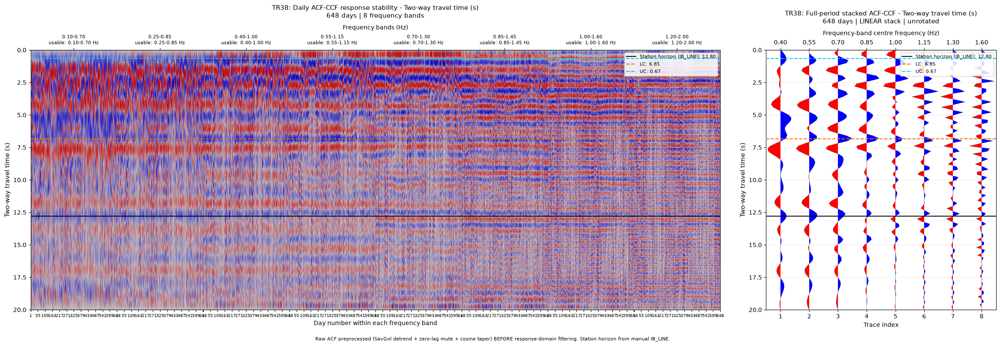

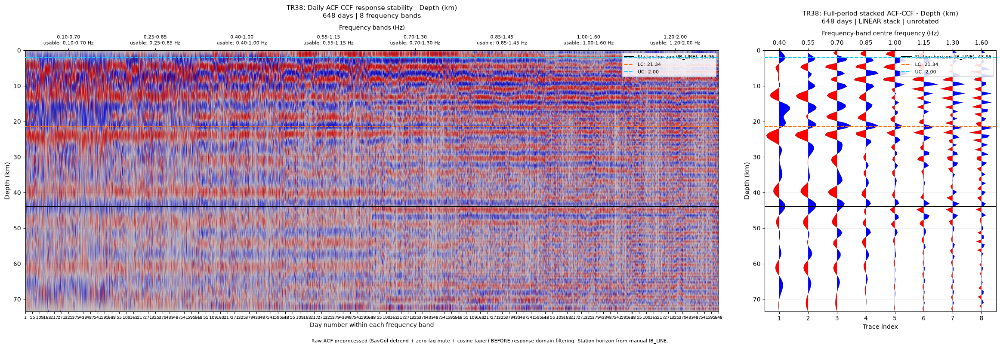

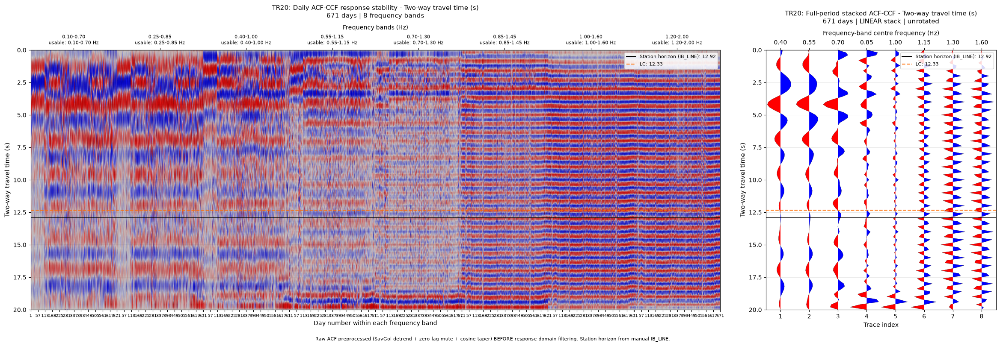

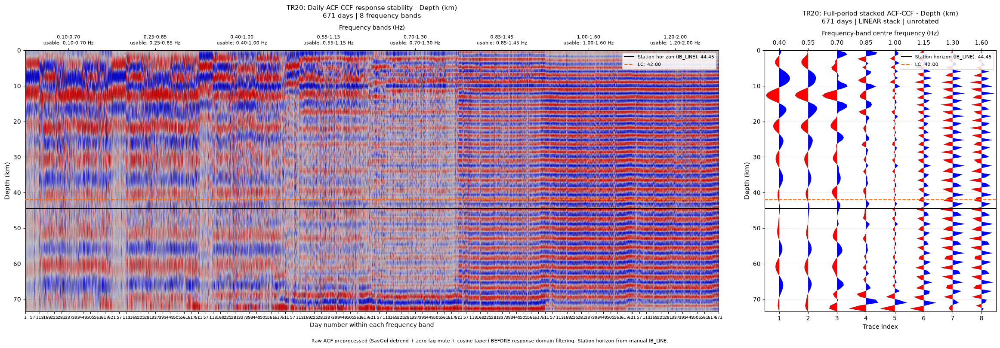

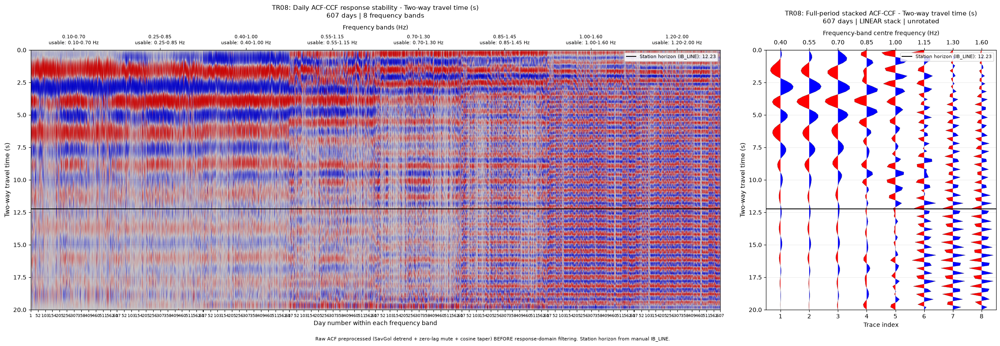

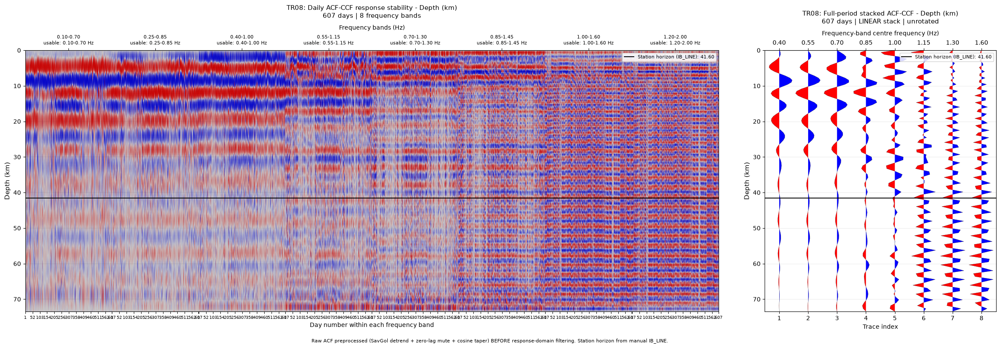

In [1]:
# stability test - TWT, depth and stack per station
import dataclasses
from pathlib import Path
import re
import calendar
import warnings
from datetime import datetime, timedelta
from scipy.signal import butter, sosfiltfilt, hilbert, savgol_filter
from scipy.interpolate import PchipInterpolator
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from obspy import read_inventory
from obspy.geodetics import gps2dist_azimuth


# ============================================================
# 1. USER SETTINGS
# ============================================================

NPY_ROOT = Path(
    r"/media/alan/JARVIS/TRANSCORBE/ACF_CCF_12_HHZ_new_2"
)

STATION = "TR26"
STATION_DIR = NPY_ROOT / STATION

# ============================================================
# STATIONS FOR MULTI-STATION COMPARISON
# ============================================================

STATIONS = [
    "TR38",
    "TR20",
    "TR08",
]

PLOT_SINGLE_STATION =  True
PLOT_MULTI_STATION = False

# Multi-station figure geometry.
MULTI_STATION_FIGSIZE = (24, 24)
MULTI_STATION_WIDTH_RATIOS = (3.0, 1.0)
MULTI_STATION_WSPACE = 0.15
MULTI_STATION_HSPACE = 0.35

# None = use the entire available period.
START_DATE = None
N_DAYS = None

DT = 0.2
MAXLAG_SEC = 20.0

SOURCE_BAND = (0.1, 2.0)

FREQUENCY_BANDS = [
    (0.10, 0.70),
    (0.25, 0.85),
    (0.40, 1.00),
    (0.55, 1.15),
    (0.70, 1.30),
    (0.85, 1.45),
    (1.00, 1.60),
    (1.20, 2.00),
]

FILTER_ORDER = 3
MIN_EFFECTIVE_BANDWIDTH_HZ = 0.20

# ============================================================
# RAW-ACF PREPROCESSING
# ============================================================

APPLY_TREND_REMOVAL = True
APPLY_ZERO_LAG_TAPER = True
APPLY_COSINE_TAPER = True

PREPROCESS_TREND_WINDOW_SEC = 4.0
PREPROCESS_TREND_POLYORDER = 2
PREPROCESS_MUTE_SEC = 3.0
PREPROCESS_COSINE_TAPER_PCT = 0.05

# ============================================================
# FREQUENCY-BAND STACK SETTINGS
# ============================================================

STACK_METHOD = "linear"
PWS_POWER = 2

APPLY_PHASE_SHIFT = False

STACK_FIGSIZE = (12, 7)
STACK_TRACE_WIDTH = 0.42
STACK_AMP_GAIN = 1.0

# ============================================================
# COMBINED FIGURE LAYOUT
# ============================================================

COMBINED_FIGSIZE = (24, 8)
COMBINED_WIDTH_RATIOS = (3.0, 1.0)
COMBINED_WSPACE = 0.10

# ============================================================
# 2. PLOT SETTINGS
# ============================================================

FIGSIZE = (20, 8)

AMP_GAIN = 5.0
TRACE_WIDTH = 0.42
NORMALIZE_EACH_TRACE = True
DISPLAY_GAIN_POWER = 0.0
MUTE_BELOW_SEC = 0.0

FILTER_FS = 1.0 / DT

STATIONXML = Path(
    r"/media/alan/JARVIS/TRANSCORBE/TRANSCORBE.xml"
)

HORIZONS_CSV = Path(
    r"/media/alan/JARVIS/TRANSCORBE/0_Round_2/wpd_datasets.csv"
)

PROFILE_START = (38.33, -3.08)
PROFILE_END = (37.43, -1.08)

MORALES_DEPTH_RANGE = (0.0, 10.0)

LC_COLOR = "#ff6d00"
UC_COLOR = "#00cfff"

# ============================================================
# 2b. MANUAL IBERIAN MOHO CONTROL POINTS
# ============================================================

IB_LINE = [
    (np.array([15, 21, 26]),
     np.array([38, 39, 42]),                       '-'),
    (np.array([26, 32, 40, 50, 57]),
     np.array([42, 44, 42, 40, 39.5]),                 '-'),
    (np.array([57, 60, 65, 70, 75, 80, 90, 98]),
     np.array([39.5, 39, 42, 47.5, 49, 47.5, 44, 45]), '-'),
    (np.array([98, 122, 130, 140, 160, 168]),
     np.array([45, 42, 40, 41.5, 46, 44.5]),       '--'),
]




# ============================================================
# 3. DEPTH CONVERSION
# ============================================================

CRUST_LAYERS = [
    (10.0, 6.0),
    (10.0, 6.4),
    (10.0, 6.8),
]

V_MANTLE = 8.2


def twt_to_moho_depth(t_twt_s):
    t_one_way = np.asarray(t_twt_s, dtype=float) / 2.0

    depth = np.zeros_like(t_one_way)
    remaining_time = t_one_way.copy()

    for thickness_km, velocity_kms in CRUST_LAYERS:
        layer_time = thickness_km / velocity_kms
        inside_layer = remaining_time <= layer_time
        depth = np.where(
            inside_layer,
            depth + remaining_time * velocity_kms,
            depth + thickness_km,
        )
        remaining_time = np.where(
            inside_layer,
            0.0,
            remaining_time - layer_time,
        )

    depth = depth + remaining_time * V_MANTLE

    if np.ndim(t_twt_s) == 0:
        return float(depth)

    return depth


def depth_to_twt(depth_km):
    remaining_depth = float(depth_km)

    if remaining_depth < 0:
        raise ValueError("Depth cannot be negative.")

    one_way_time = 0.0

    for thickness, velocity in CRUST_LAYERS:
        if remaining_depth <= thickness:
            one_way_time += remaining_depth / velocity
            remaining_depth = 0.0
            break
        one_way_time += thickness / velocity
        remaining_depth -= thickness

    if remaining_depth > 0:
        one_way_time += remaining_depth / V_MANTLE

    return 2.0 * one_way_time


def get_station_profile_distance(station):
    if not STATIONXML.exists():
        raise FileNotFoundError(
            f"StationXML not found: {STATIONXML}"
        )

    inventory = read_inventory(str(STATIONXML))

    station_coords = {
        sta.code: (sta.latitude, sta.longitude)
        for net in inventory
        for sta in net
    }

    if station not in station_coords:
        raise ValueError(
            f"Station {station} was not found in StationXML."
        )

    lat, lon = station_coords[station]

    _, profile_azimuth, _ = gps2dist_azimuth(
        PROFILE_START[0], PROFILE_START[1],
        PROFILE_END[0], PROFILE_END[1]
    )

    distance_m, station_azimuth, _ = gps2dist_azimuth(
        PROFILE_START[0], PROFILE_START[1],
        lat, lon
    )

    projected_km = (
        distance_m
        * np.cos(np.deg2rad(station_azimuth - profile_azimuth))
        / 1000.0
    )

    return projected_km


def iberian_moho_depth_at_profile_km(profile_km):
    for xs, ys, _ in IB_LINE:
        if xs.min() <= profile_km <= xs.max():
            return float(PchipInterpolator(xs, ys)(profile_km))

    raise ValueError(
        f"Profile distance {profile_km:.2f} km is outside the "
        f"IB_LINE range "
        f"({IB_LINE[0][0].min():.0f}-{IB_LINE[-1][0].max():.0f} km)."
    )


def load_morales_lc_uc_at_station(station):
    if not HORIZONS_CSV.is_file():
        raise FileNotFoundError(
            f"Morales horizon CSV not found: {HORIZONS_CSV}"
        )

    station_distance = get_station_profile_distance(station)

    df = pd.read_csv(HORIZONS_CSV, header=1)

    expected_columns = [
        "IbMoho_x", "IbMoho_y",
        "AlbMoho_x", "AlbMoho_y",
        "LC_x", "LC_y",
        "UC_x", "UC_y",
        "Tear_x", "Tear_y",
    ]

    if len(df.columns) != len(expected_columns):
        raise ValueError(
            "Unexpected CSV column count. Check the header."
        )

    df.columns = expected_columns

    depth_lines = []
    twt_lines = []

    horizons = [
        ("LC", "LC_x", "LC_y", LC_COLOR),
        ("UC", "UC_x", "UC_y", UC_COLOR),
    ]

    print(
        f"\nMorales LC/UC positions at {station}: "
        f"profile distance = {station_distance:.2f} km"
    )

    for name, xcol, ycol, colour in horizons:
        x = pd.to_numeric(df[xcol], errors="coerce").to_numpy(dtype=float)
        depth_values = pd.to_numeric(
            df[ycol], errors="coerce"
        ).to_numpy(dtype=float)

        valid = np.isfinite(x) & np.isfinite(depth_values)
        x = x[valid]
        depth_values = depth_values[valid]

        if len(x) < 2:
            print(f"{name}: insufficient valid CSV points.")
            continue

        order = np.argsort(x)
        x = x[order]
        depth_values = depth_values[order]

        if not (x.min() <= station_distance <= x.max()):
            print(
                f"{name}: station distance is outside "
                "the digitized profile range."
            )
            continue

        depth = float(np.interp(station_distance, x, depth_values))
        twt = depth_to_twt(depth)

        depth_lines.append((name, depth, colour))
        twt_lines.append((name, twt, colour))

        print(
            f"{name}: depth = {depth:.2f} km | "
            f"TWT = {twt:.2f} s"
        )

    return depth_lines, twt_lines


# ============================================================
# 4. DATE EXTRACTION
# ============================================================

def date_from_filename(path):
    name = path.name

    match = re.search(r"(?<!\d)(\d{8})(?!\d)", name)
    if match:
        try:
            return datetime.strptime(
                match.group(1), "%Y%m%d"
            ).date()
        except ValueError:
            pass

    match = re.search(
        r"(?<!\d)(\d{4})[-_.](\d{2})[-_.](\d{2})(?!\d)", name,
    )
    if match:
        try:
            return datetime.strptime(
                "-".join(match.groups()), "%Y-%m-%d"
            ).date()
        except ValueError:
            pass

    match = re.search(r"(?<!\d)(\d{4})[._-](\d{3})(?!\d)", name)
    if not match:
        match = re.search(r"(?<!\d)(\d{4})(\d{3})(?!\d)", name)

    if match:
        year = int(match.group(1))
        jday = int(match.group(2))
        max_jday = 366 if calendar.isleap(year) else 365

        if 1 <= jday <= max_jday:
            return (
                datetime(year, 1, 1).date()
                + timedelta(days=jday - 1)
            )

    return None


# ============================================================
# 5. COLLECT DAILY NPY FILES
# ============================================================

def collect_daily_npy(folder):
    if not folder.is_dir():
        raise FileNotFoundError(
            f"Station folder not found: {folder}"
        )

    files = sorted(folder.glob("*_acf_ccf.npy"))
    if not files:
        files = sorted(folder.glob("*.npy"))

    dated = {}
    for file in files:
        day = date_from_filename(file)

        if day is None:
            warnings.warn(
                f"Ignoring file without a recognizable date: "
                f"{file.name}"
            )
            continue

        if day in dated:
            warnings.warn(
                f"Duplicate date {day}: keeping {dated[day].name}"
            )
            continue

        dated[day] = file

    if not dated:
        raise ValueError(
            f"No dated NPY files found in {folder}"
        )

    return dated


# ============================================================
# 6. SELECT DATES
# ============================================================

def select_date_window(dated_files, start_date=None, n_days=None):
    available = sorted(dated_files)

    if not available:
        raise ValueError("No dated NPY files available.")

    if start_date is None and n_days is None:
        return [(day, dated_files[day]) for day in available]

    if n_days is None:
        start = datetime.strptime(start_date, "%Y-%m-%d").date()
        selected = [
            (day, dated_files[day])
            for day in available
            if day >= start
        ]
        if not selected:
            raise ValueError(
                f"No recordings found on or after {start}."
            )
        return selected

    if start_date is None:
        for start in available:
            targets = [
                start + timedelta(days=i)
                for i in range(n_days)
            ]
            if all(day in dated_files for day in targets):
                return [
                    (day, dated_files[day])
                    for day in targets
                ]
        raise ValueError(
            f"No complete {n_days}-day interval was found."
        )

    start = datetime.strptime(start_date, "%Y-%m-%d").date()
    targets = [start + timedelta(days=i) for i in range(n_days)]
    missing = [day for day in targets if day not in dated_files]

    if missing:
        raise ValueError(
            "Missing dates: " + ", ".join(str(day) for day in missing)
        )

    return [(day, dated_files[day]) for day in targets]


# ============================================================
# 6b. PREPROCESS RAW AUTOCORRELATIONS
# ============================================================

def remove_trend(
    acf,
    dt=DT,
    window_sec=PREPROCESS_TREND_WINDOW_SEC,
    polyorder=PREPROCESS_TREND_POLYORDER,
):
    window = int(window_sec / dt)
    if window % 2 == 0:
        window += 1
    trend = savgol_filter(np.asarray(acf, dtype=float), window, polyorder)
    return np.asarray(acf, dtype=float) - trend


def zero_lag_taper(acf, dt=DT, mute_sec=PREPROCESS_MUTE_SEC):
    n = len(acf)
    mute_samples = int(round(mute_sec / dt))
    if mute_samples < 1:
        return acf.copy()
    if mute_samples >= n:
        return np.zeros_like(acf)
    window = np.ones(n)
    window[:mute_samples] = np.sin(
        np.linspace(0.0, np.pi / 2.0, mute_samples)
    ) ** 2
    return acf * window


def cosine_taper(n, pct=PREPROCESS_COSINE_TAPER_PCT):
    m = int(pct * n)
    if m < 1:
        return np.ones(n)
    w = np.ones(n)
    taper = np.sin(np.linspace(0.0, np.pi / 2.0, m)) ** 2
    w[:m] = taper
    w[-m:] = taper[::-1]
    return w


def preprocess_raw_acf(trace):
    x = np.asarray(trace, dtype=float).copy()

    if APPLY_TREND_REMOVAL:
        x = remove_trend(x)
    if APPLY_ZERO_LAG_TAPER:
        x = zero_lag_taper(x)
    if APPLY_COSINE_TAPER:
        x = x * cosine_taper(x.size)

    return x


def preprocess_daily_traces(daily):
    return np.vstack([
        preprocess_raw_acf(row)
        for row in np.asarray(daily, dtype=float)
    ])


# ============================================================
# 7. LOAD DAILY RESPONSES
# ============================================================

def load_daily_responses(selected_files):
    expected_n = int(round(MAXLAG_SEC / DT)) + 1
    traces = []

    for day, path in selected_files:
        arr = np.asarray(
            np.load(path, allow_pickle=False),
            dtype=float,
        ).squeeze()

        if arr.ndim != 1:
            raise ValueError(
                f"{path.name}: expected 1-D array; "
                f"received {arr.shape}"
            )

        if arr.size != expected_n:
            raise ValueError(
                f"{path.name}: expected {expected_n} samples "
                f"for 0-{MAXLAG_SEC:g} s at DT={DT:g} s; "
                f"received {arr.size}."
            )

        arr = np.nan_to_num(arr, nan=0.0, posinf=0.0, neginf=0.0)
        traces.append(arr)

    return np.vstack(traces)


# ============================================================
# 8. DETERMINE USABLE FREQUENCY BANDS
# ============================================================

def effective_band(fmin, fmax):
    nyquist = FILTER_FS / 2.0
    lo = max(fmin, SOURCE_BAND[0])
    hi = min(fmax, SOURCE_BAND[1], 0.98 * nyquist)

    if hi - lo < MIN_EFFECTIVE_BANDWIDTH_HZ:
        return None

    return lo, hi


# ============================================================
# 9. FILTER THE SAVED RESPONSE
# ============================================================

def filter_response_trace(trace, fmin, fmax):
    sos = butter(
        FILTER_ORDER,
        [fmin, fmax],
        btype="bandpass",
        fs=FILTER_FS,
        output="sos",
    )
    return sosfiltfilt(sos, trace)


# ============================================================
# 10. PREPARE TRACE AMPLITUDES FOR DISPLAY
# ============================================================

def prepare_trace_for_display(trace, lag_s):
    x = np.asarray(trace, dtype=float).copy()

    if MUTE_BELOW_SEC > 0:
        x[lag_s < MUTE_BELOW_SEC] = 0.0

    if DISPLAY_GAIN_POWER != 0:
        t0 = max(DT, 0.1)
        gain = (np.maximum(lag_s, t0) / t0) ** DISPLAY_GAIN_POWER
        x *= gain

    if NORMALIZE_EACH_TRACE:
        scale = np.percentile(np.abs(x), 99)
        if np.isfinite(scale) and scale > 0:
            x /= scale

    return x


# ============================================================
# 11. STATION HORIZON FROM MANUAL IBERIAN MOHO (IB_LINE)
# ============================================================

def get_station_horizon(station=STATION):
    station_distance = get_station_profile_distance(station)
    horizon_depth = iberian_moho_depth_at_profile_km(station_distance)
    horizon_twt = depth_to_twt(horizon_depth)

    if not np.isfinite(horizon_twt):
        raise ValueError(
            f"Invalid horizon pick for {station}."
        )

    if not 0 <= horizon_twt <= MAXLAG_SEC:
        raise ValueError(
            f"Horizon TWT {horizon_twt:.2f} s is outside "
            "the plotted lag interval."
        )

    print(
        f"\nIberian Moho (IB_LINE) at {station}: "
        f"profile distance = {station_distance:.2f} km"
    )
    print(
        f"  depth = {horizon_depth:.2f} km | "
        f"TWT   = {horizon_twt:.2f} s"
    )

    return horizon_twt, horizon_depth


# ============================================================
# 11b. PHASE ROTATION + STACKING HELPERS
# ============================================================

def phase_shift(trace, dt=DT):
    x = np.asarray(trace, dtype=float)
    n = x.size
    freqs = np.fft.fftfreq(n, d=dt)
    F = np.fft.fft(x)
    ps = np.where(
        freqs > 0,
        np.exp(-1j * np.pi / 2.0),
        np.where(freqs < 0, np.exp(1j * np.pi / 2.0), 1.0),
    )
    return np.real(np.fft.ifft(F * ps))


def stack_daily_responses(
    traces, method="linear", power=2, apply_phase_shift=False,
):
    traces = np.asarray(traces, dtype=float)

    if method.lower() == "linear":
        linear = np.mean(traces, axis=0)
        if apply_phase_shift:
            linear = phase_shift(linear)
        return linear

    if method.lower() == "pws":
        if apply_phase_shift:
            traces = np.vstack([phase_shift(tr) for tr in traces])
        linear = np.mean(traces, axis=0)
        analytic = hilbert(traces, axis=1)
        amplitude = np.abs(analytic)
        unit_phase = analytic / np.maximum(amplitude, 1e-10)
        phase_coherence = np.abs(np.mean(unit_phase, axis=0))
        return linear * phase_coherence**power

    raise ValueError(
        "STACK_METHOD must be 'linear' or 'pws'."
    )


# ============================================================
# 12. DRAW ONE PANEL (stability)
# ============================================================

def draw_stability_panel(
    ax,
    dates,
    filtered_responses,
    bands,
    y_values,
    horizon_value,
    station,
    axis_label,
    reference_horizons=None,
):
    n_days = len(dates)
    n_bands = len(bands)
    total_traces = n_days * n_bands

    band_centres = []
    band_labels = []
    bottom_ticks = []
    bottom_labels = []

    for ib, (
        nominal_lo,
        nominal_hi,
        effective_lo,
        effective_hi,
    ) in enumerate(bands):

        group_start = ib * n_days
        band_centres.append(group_start + (n_days - 1) / 2.0)
        band_labels.append(
            f"{nominal_lo:.2f}-{nominal_hi:.2f}\n"
            f"usable: {effective_lo:.2f}-{effective_hi:.2f} Hz"
        )

        for iday in range(n_days):
            response = filtered_responses[(ib, iday)]
            x0 = group_start + iday
            x = x0 + TRACE_WIDTH * AMP_GAIN * response

            positive = response >= 0
            negative = response < 0

            ax.fill_betweenx(
                y_values, x0, x, where=positive,
                facecolor="blue", edgecolor="blue",
                linewidth=0, interpolate=True, zorder=2,
            )
            ax.fill_betweenx(
                y_values, x0, x, where=negative,
                facecolor="red", edgecolor="red",
                linewidth=0, interpolate=True, zorder=2,
            )
            ax.plot(
                x, y_values, color="black",
                linewidth=0.12, alpha=0.45, zorder=3,
            )

        tick_step = max(1, int(np.ceil(n_days / 12)))
        tick_days = list(range(1, n_days + 1, tick_step))
        if n_days not in tick_days:
            tick_days.append(n_days)

        for day_number in tick_days:
            bottom_ticks.append(group_start + day_number - 1)
            bottom_labels.append(str(day_number))

    ax.set_xlim(-0.5, total_traces - 0.5)
    ax.set_ylim(float(np.nanmax(y_values)), 0.0)

    ax.set_ylabel(axis_label, fontsize=11)
    ax.set_xlabel(
        "Day number within each frequency band",
        fontsize=10,
    )
    ax.set_xticks(bottom_ticks)
    ax.set_xticklabels(bottom_labels, fontsize=7)

    ax.grid(axis="y", color="0.75", linewidth=0.35, alpha=0.6)

    ax.axhline(
        horizon_value, color="black", linewidth=1.4,
        linestyle="-", zorder=10,
        label=f"Station horizon (IB_LINE): {horizon_value:.2f}",
    )

    for name, value, colour in (reference_horizons or []):
        if np.nanmin(y_values) <= value <= np.nanmax(y_values):
            ax.axhline(
                value, color=colour, linewidth=1.5,
                linestyle="--", zorder=9,
                label=f"{name}: {value:.2f}",
            )

    ax.set_title(
        f"{station}: Daily ACF-CCF response stability - {axis_label}\n"
        f"{n_days} days | {n_bands} frequency bands",
        fontsize=11,
        pad=12,
    )

    top = ax.secondary_xaxis("top")
    top.set_xticks(band_centres)
    top.set_xticklabels(band_labels, fontsize=8)
    top.set_xlabel("Frequency bands (Hz)", labelpad=8)

    ax.legend(loc="upper right", fontsize=8, framealpha=0.85)


# ============================================================
# 13. DRAW ONE PANEL (stacked)
# ============================================================

def draw_stack_panel(
    ax,
    stacked_responses,
    bands,
    y_values,
    horizon_value,
    station,
    n_days,
    axis_label,
    reference_horizons=None,
):
    n_bands = len(bands)
    trace_indices = np.arange(1, n_bands + 1)
    centre_frequencies = []

    for ib, (
        nominal_lo,
        nominal_hi,
        effective_lo,
        effective_hi,
    ) in enumerate(bands):

        response = np.asarray(
            stacked_responses[ib], dtype=float
        ).copy()

        if NORMALIZE_EACH_TRACE:
            scale = np.percentile(np.abs(response), 99)
            if np.isfinite(scale) and scale > 0:
                response /= scale

        if DISPLAY_GAIN_POWER != 0:
            lag_local = np.arange(len(response)) * DT
            t0 = max(DT, 0.1)
            response *= (
                np.maximum(lag_local, t0) / t0
            ) ** DISPLAY_GAIN_POWER

        x0 = trace_indices[ib]
        x = x0 + STACK_TRACE_WIDTH * STACK_AMP_GAIN * response

        positive = response >= 0
        negative = response < 0

        ax.fill_betweenx(
            y_values, x0, x, where=positive,
            facecolor="blue", edgecolor="blue",
            linewidth=0, interpolate=True, zorder=2,
        )
        ax.fill_betweenx(
            y_values, x0, x, where=negative,
            facecolor="red", edgecolor="red",
            linewidth=0, interpolate=True, zorder=2,
        )
        ax.plot(
            x, y_values, color="black",
            linewidth=0.35, alpha=0.65, zorder=3,
        )

        centre_frequencies.append(
            (effective_lo + effective_hi) / 2.0
        )

    ax.set_xlim(0.5, n_bands + 0.5)
    ax.set_ylim(float(np.nanmax(y_values)), 0.0)

    ax.set_xticks(trace_indices)
    ax.set_xticklabels([str(i) for i in trace_indices])
    ax.set_xlabel("Trace index", fontsize=10)
    ax.set_ylabel(axis_label, fontsize=11)

    shift_tag = (
        "phase-rotated (90 deg)"
        if APPLY_PHASE_SHIFT
        else "unrotated"
    )

    ax.set_title(
        f"{station}: Full-period stacked ACF-CCF - {axis_label}\n"
        f"{n_days} days | {STACK_METHOD.upper()} stack | {shift_tag}",
        fontsize=11,
        pad=12,
    )

    top = ax.secondary_xaxis("top")
    top.set_xticks(trace_indices)
    top.set_xticklabels([f"{f:.2f}" for f in centre_frequencies])
    top.set_xlabel(
        "Frequency-band centre frequency (Hz)", labelpad=8,
    )

    ax.axhline(
        horizon_value, color="black", linewidth=1.4,
        linestyle="-", zorder=10,
        label=f"Station horizon (IB_LINE): {horizon_value:.2f}",
    )

    for name, value, colour in (reference_horizons or []):
        if np.nanmin(y_values) <= value <= np.nanmax(y_values):
            ax.axhline(
                value, color=colour, linewidth=1.5,
                linestyle="--", zorder=9,
                label=f"{name}: {value:.2f}",
            )

    ax.legend(loc="upper right", fontsize=8, framealpha=0.85)
    ax.grid(axis="y", color="0.75", linewidth=0.4, alpha=0.6)


# ============================================================
# 13b. COMBINED SINGLE-STATION FIGURE
# ============================================================

def plot_combined_stability_stack(
    dates,
    filtered_responses,
    stacked_responses,
    bands,
    y_values,
    horizon_value,
    station,
    axis_label,
    title_suffix,
    reference_horizons=None,
):
    n_days = len(dates)

    fig, (ax_left, ax_right) = plt.subplots(
        1, 2,
        figsize=COMBINED_FIGSIZE,
        gridspec_kw={"width_ratios": COMBINED_WIDTH_RATIOS},
    )

    draw_stability_panel(
        ax_left,
        dates=dates,
        filtered_responses=filtered_responses,
        bands=bands,
        y_values=y_values,
        horizon_value=horizon_value,
        station=station,
        axis_label=axis_label,
        reference_horizons=reference_horizons,
    )

    draw_stack_panel(
        ax_right,
        stacked_responses=stacked_responses,
        bands=bands,
        y_values=y_values,
        horizon_value=horizon_value,
        station=station,
        n_days=n_days,
        axis_label=axis_label,
        reference_horizons=reference_horizons,
    )

    fig.text(
        0.5, 0.01,
        "Raw ACF preprocessed (SavGol detrend + zero-lag mute + "
        "cosine taper) BEFORE response-domain filtering. "
        "Station horizon from manual IB_LINE.",
        ha="center", fontsize=8,
    )

    fig.subplots_adjust(
        left=0.05, right=0.99,
        bottom=0.10, top=0.86,
        wspace=COMBINED_WSPACE,
    )

    plt.show()
    plt.close(fig)


# ============================================================
# 13c. SINGLE-STATION WRAPPER
# ============================================================

def plot_single_station_combined(result, metric="twt"):
    if metric == "twt":
        y_values = result["lag_s"]
        horizon = result["horizon_twt"]
        refs = result["morales_twt_lines"]
        axis_label = "Two-way travel time (s)"
    elif metric == "depth":
        y_values = twt_to_moho_depth(result["lag_s"])
        horizon = result["horizon_depth"]
        refs = result["morales_depth_lines"]
        axis_label = "Depth (km)"
    else:
        raise ValueError("metric must be 'twt' or 'depth'")

    plot_combined_stability_stack(
        dates=result["dates"],
        filtered_responses=result["filtered_responses"],
        stacked_responses=result["stacked_responses"],
        bands=result["valid_bands"],
        y_values=y_values,
        horizon_value=horizon,
        station=result["station"],
        axis_label=axis_label,
        title_suffix=axis_label,
        reference_horizons=refs,
    )


# ============================================================
# 13d. PER-STATION PIPELINE
# ============================================================

def process_station(station):
    print("\n" + "=" * 65)
    print(f"Processing station: {station}")
    print("=" * 65)

    station_dir = NPY_ROOT / station

    dated_files = collect_daily_npy(station_dir)
    selected_files = select_date_window(
        dated_files, START_DATE, N_DAYS
    )
    dates = [day for day, _ in selected_files]

    daily = load_daily_responses(selected_files)
    print(
        f"{station}: preprocessing {len(dates)} daily ACFs "
        "(trend removal -> zero-lag mute -> cosine taper)..."
    )
    daily = preprocess_daily_traces(daily)

    lag_s = np.arange(daily.shape[1], dtype=float) * DT

    print(f"  date range: {dates[0]} to {dates[-1]}")
    print(f"  input shape: {daily.shape} | DT = {DT:g} s")

    valid_bands = []
    for lo, hi in FREQUENCY_BANDS:
        effective = effective_band(lo, hi)
        if effective is not None:
            valid_bands.append((lo, hi, effective[0], effective[1]))

    if not valid_bands:
        raise ValueError(f"{station}: no usable frequency bands.")

    print("  usable bands:")
    for lo, hi, elo, ehi in valid_bands:
        print(
            f"    {lo:.2f}-{hi:.2f} Hz "
            f"(effective {elo:.2f}-{ehi:.2f} Hz)"
        )

    horizon_twt, horizon_depth = get_station_horizon(station)
    morales_depth_lines, morales_twt_lines = (
        load_morales_lc_uc_at_station(station)
    )

    filtered_responses = {}
    filtered_raw_responses = {}

    for ib, (_, _, elo, ehi) in enumerate(valid_bands):
        for iday in range(len(dates)):
            raw_trace = filter_response_trace(daily[iday], elo, ehi)
            filtered_raw_responses[(ib, iday)] = raw_trace.copy()
            filtered_responses[(ib, iday)] = prepare_trace_for_display(
                raw_trace, lag_s
            )

    stacked_responses = {}
    for ib in range(len(valid_bands)):
        band_traces = np.vstack([
            filtered_raw_responses[(ib, iday)]
            for iday in range(len(dates))
        ])
        stacked_responses[ib] = stack_daily_responses(
            band_traces,
            method=STACK_METHOD,
            power=PWS_POWER,
            apply_phase_shift=APPLY_PHASE_SHIFT,
        )

    print(
        f"  stacked {len(stacked_responses)} bands | "
        f"{STACK_METHOD.upper()} | phase-shift "
        f"{'ON (90 deg)' if APPLY_PHASE_SHIFT else 'OFF'}"
    )

    return {
        "station": station,
        "dates": dates,
        "lag_s": lag_s,
        "valid_bands": valid_bands,
        "filtered_responses": filtered_responses,
        "stacked_responses": stacked_responses,
        "horizon_twt": horizon_twt,
        "horizon_depth": horizon_depth,
        "morales_twt_lines": morales_twt_lines,
        "morales_depth_lines": morales_depth_lines,
    }


# ============================================================
# 13e. MULTI-STATION FIGURE  (one row per station, 2 cols)
# ============================================================

def plot_multi_station_comparison(station_results, metric="twt"):
    n_stations = len(station_results)
    if n_stations == 0:
        return

    if metric == "twt":
        h_key = "horizon_twt"
        ref_key = "morales_twt_lines"
        axis_label = "Two-way travel time (s)"
    elif metric == "depth":
        h_key = "horizon_depth"
        ref_key = "morales_depth_lines"
        axis_label = "Depth (km)"
    else:
        raise ValueError("metric must be 'twt' or 'depth'")

    for r in station_results:
        r["_y"] = (
            r["lag_s"] if metric == "twt"
            else twt_to_moho_depth(r["lag_s"])
        )

    row_height = MULTI_STATION_FIGSIZE[1] / 3.0

    fig, axes = plt.subplots(
        n_stations, 2,
        figsize=(MULTI_STATION_FIGSIZE[0], row_height * n_stations),
        gridspec_kw={
            "width_ratios": MULTI_STATION_WIDTH_RATIOS,
            "wspace": MULTI_STATION_WSPACE,
            "hspace": MULTI_STATION_HSPACE,
        },
        sharey=True,
        squeeze=False,
    )

    for i, r in enumerate(station_results):

        draw_stability_panel(
            axes[i, 0],
            dates=r["dates"],
            filtered_responses=r["filtered_responses"],
            bands=r["valid_bands"],
            y_values=r["_y"],
            horizon_value=r[h_key],
            station=r["station"],
            axis_label=axis_label,
            reference_horizons=r[ref_key],
        )

        draw_stack_panel(
            axes[i, 1],
            stacked_responses=r["stacked_responses"],
            bands=r["valid_bands"],
            y_values=r["_y"],
            horizon_value=r[h_key],
            station=r["station"],
            n_days=len(r["dates"]),
            axis_label=axis_label,
            reference_horizons=r[ref_key],
        )

        # ----- Row label (a, b, c, …) ------------------------
        row_label = chr(ord("a") + i)

        for ax in (axes[i, 0], axes[i, 1]):
            ax.annotate(
                f"({row_label})",
                xy=(-0.06, 1.06),
                xycoords="axes fraction",
                ha="right",
                va="bottom",
                fontsize=16,
                fontweight="bold",
                clip_on=False,
            )

    fig.subplots_adjust(
        left=0.05,
        right=0.98,
        bottom=0.05,
        top=0.92,
        wspace=MULTI_STATION_WSPACE,
        hspace=MULTI_STATION_HSPACE,
    )

    plt.show()
    plt.close(fig)


# ============================================================
# 14. MAIN
# ============================================================

def main():
    station_results = [process_station(s) for s in STATIONS]

    if PLOT_SINGLE_STATION:
        for r in station_results:
            plot_single_station_combined(r, metric="twt")
            plot_single_station_combined(r, metric="depth")

    if PLOT_MULTI_STATION:
        plot_multi_station_comparison(station_results, metric="twt")
        plot_multi_station_comparison(station_results, metric="depth")


if __name__ == "__main__":
    main()